In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split, GridSearchCV

In [ ]:
tennis_data = pd.read_csv('/content/play.csv')

In [ ]:
tennis_data = pd.get_dummies(tennis_data, columns=['outlook','temp','humidity','wind'], drop_first=True)

In [ ]:
tennis_data.head(5)

,day,play,outlook_Rain,outlook_Sunny,temp_Hot,temp_Mild,humidity_Normal,wind_Weak
0,D1,No,False,True,True,False,False,True
1,D2,No,False,True,True,False,False,False
2,D3,Yes,False,False,True,False,False,True
3,D4,Yes,True,False,False,True,False,True
4,D5,Yes,True,False,False,False,True,True


In [ ]:
tennis_data1 = pd.read_csv('/content/play.csv')
encoders={}
for column in ['outlook', 'temp', 'humidity', 'wind', 'play']:
    le = LabelEncoder()
    tennis_data1[column] = le.fit_transform(tennis_data1[column])
    encoders[column] = le

In [ ]:
tennis_data1

,day,outlook,temp,humidity,wind,play
0,D1,2,1,0,1,0
1,D2,2,1,0,0,0
2,D3,0,1,0,1,1
3,D4,1,2,0,1,1
4,D5,1,0,1,1,1
5,D6,1,0,1,0,0
6,D7,0,0,1,0,1
7,D8,2,2,0,1,0
8,D9,2,0,1,1,1
9,D10,1,2,1,1,1


In [ ]:
y = tennis_data['play']
x = tennis_data.drop(['play', 'day'], axis=1)

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.5, random_state=0)

In [ ]:
clf = DecisionTreeClassifier(criterion='entropy')
clf.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy')

|--- temp_Mild <= 0.50
|   |--- humidity_Normal <= 0.50
|   |   |--- class: No
|   |--- humidity_Normal >  0.50
|   |   |--- outlook_Rain <= 0.50
|   |   |   |--- class: Yes
|   |   |--- outlook_Rain >  0.50
|   |   |   |--- class: No
|--- temp_Mild >  0.50
|   |--- outlook_Sunny <= 0.50
|   |   |--- class: Yes
|   |--- outlook_Sunny >  0.50
|   |   |--- wind_Weak <= 0.50
|   |   |   |--- class: Yes
|   |   |--- wind_Weak >  0.50
|   |   |   |--- class: No



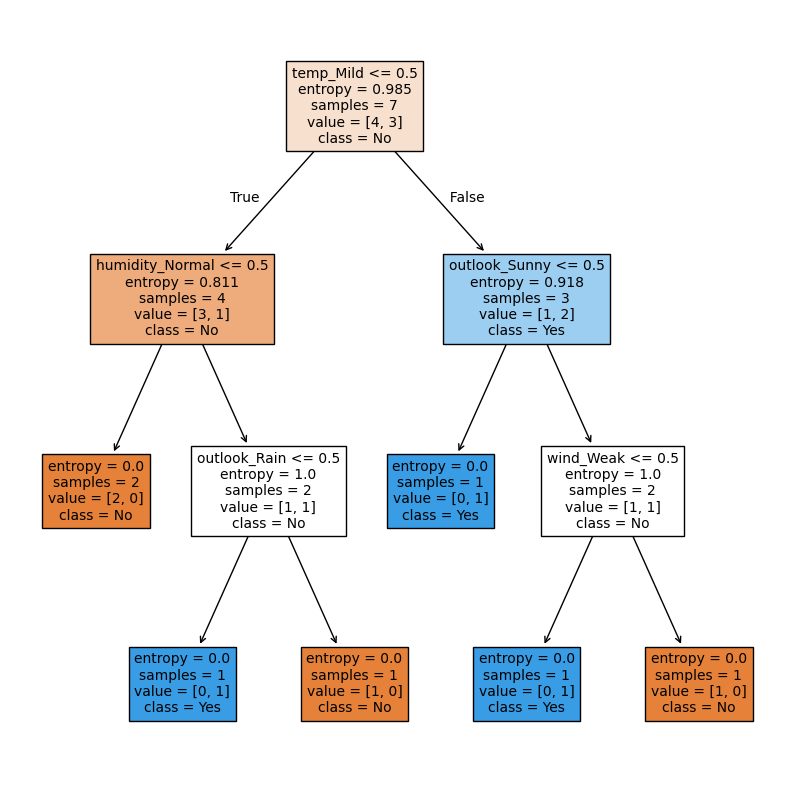

In [ ]:
print(export_text(clf, feature_names=list(x.columns)))
fig, ax = plt.subplots(figsize=(10, 10))
plot_tree(clf, feature_names=x.columns, class_names=["No", "Yes"], fontsize=10, filled=True)
plt.show()

In [ ]:
y_pred = clf.predict(x_test)

In [ ]:
y_pred

array(['Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes'], dtype=object)

In [ ]:
y_test

,play
8,Yes
6,Yes
4,Yes
11,Yes
2,Yes
13,No
9,Yes


In [ ]:
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

          No       0.00      0.00      0.00         1
         Yes       0.80      0.67      0.73         6

    accuracy                           0.57         7
   macro avg       0.40      0.33      0.36         7
weighted avg       0.69      0.57      0.62         7

Accuracy: 0.5714285714285714



Best Parameters Found: {'criterion': 'entropy', 'max_depth': 2, 'min_samples_split': 2}

Accuracy: 0.7142857142857143

Classification Report:
               precision    recall  f1-score   support

          No       0.33      1.00      0.50         1
         Yes       1.00      0.67      0.80         6

    accuracy                           0.71         7
   macro avg       0.67      0.83      0.65         7
weighted avg       0.90      0.71      0.76         7



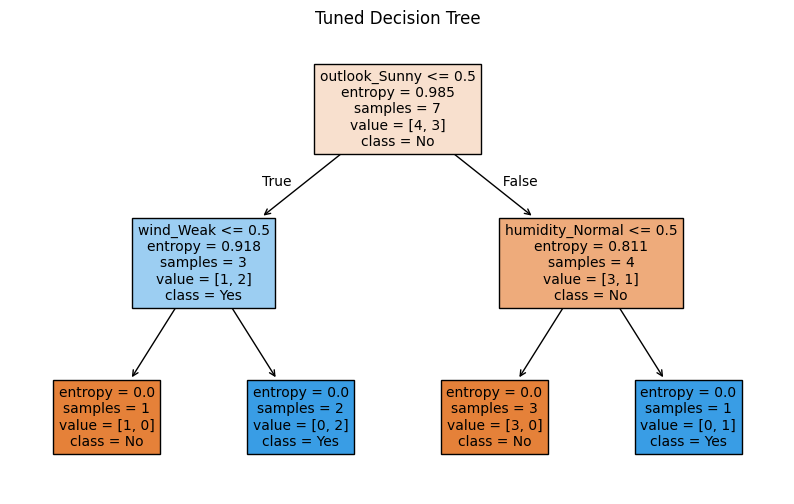

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [2],
    'min_samples_split': [2, 4],
    'criterion': ['entropy']
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=0),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(x_train, y_train)

best_model = grid_search.best_estimator_
print("\nBest Parameters Found:", grid_search.best_params_)

y_pred_best = best_model.predict(x_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred_best))
print("\nClassification Report:\n", classification_report(y_test, y_pred_best))

plt.figure(figsize=(10, 6))
plot_tree(best_model, feature_names=x.columns, class_names=["No", "Yes"],
          fontsize=10, filled=True)
plt.title("Tuned Decision Tree")
plt.show()